# Financial Fraud Detection: from transactions to review decisions

**A reproducible and explainable, CPU-only workshop for Databricks and Google Colab.**

By: Servio Palacios, Ph.D. and his Digital Twin.

By the end, you will be able to audit a labeled transaction dataset, explain a decision tree,
compare supervised classification with anomaly detection, select a decision threshold using
validation data, and interpret an untouched chronological test set.

The workflow is: **load → audit → chronological split → training-only exploration → fit →
validation selection → threshold selection → final test → score/export**.

Every code cell has an explanation. Run the notebook in order. No GPU, Spark cluster,
Kaggle credentials, or TensorFlow installation is required. This is a pandas/scikit-learn
workflow on the Databricks driver; it is not a distributed Spark benchmark.

**Dataset:** ULB/Worldline credit-card transactions, not PaySim (orginal Databricks demo) from the older linked demo.

Results from these two datasets are not directly comparable. References appear at the end.


## 1. Open the notebook and prepare the environment

**Colab:** open https://colab.research.google.com/ → File → Upload notebook → select this
`.ipynb` → connect to a Python CPU runtime. 
The loader downloads the CSV automatically.
For offline loading, upload `creditcard.csv` through the Files panel first.

**Databricks:** Workspace → choose a folder → Import → File → select this `.ipynb`
(or the supplied Databricks `.py` source) → attach Python compute → Run all.

Use Python 3.11+ with pandas, NumPy, matplotlib, scikit-learn, and IPython available.
Databricks ML compute is convenient; a compatible Python serverless environment also works.

If internet access is restricted, upload the CSV to a Unity Catalog volume and set
`LOCAL_DATA_PATH` below to `/Volumes/<catalog>/<schema>/<volume>/creditcard.csv`.

If dependencies are missing, install the following in a **separate setup cell**, restart
Python if your platform asks, then rerun this notebook from the top:

```python
%pip install pandas==2.2.3 numpy==2.3.5 scikit-learn==1.8.0 matplotlib==3.10.8
```

Those are the versions used for the accompanying verification. Other compatible versions
can produce small numerical differences. The core uses scikit-learn APIs available in 1.4+.


In [0]:
from pathlib import Path
import hashlib
import json
import platform
import shutil
import sys
import tempfile
import time
import urllib.request

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, confusion_matrix,
    ConfusionMatrixDisplay, f1_score, precision_recall_curve,
    precision_score, recall_score, roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

SEED = 42
LOCAL_DATA_PATH = ''  # Set only if you already have creditcard.csv.
OUTPUT_DIR = Path(tempfile.gettempdir()) / 'fraud_demo_outputs'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RUN_MLFLOW = False  # Optional section; the core demo does not need MLflow.
MLFLOW_EXPERIMENT = ''  # Databricks: supply an experiment path you can write to.

versions = {
    'python': platform.python_version(), 'numpy': np.__version__,
    'pandas': pd.__version__, 'scikit_learn': sklearn.__version__,
    'matplotlib': matplotlib.__version__,
}
display(pd.Series(versions, name='version').to_frame())
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.grid': False})


,version
python,3.12.3
numpy,2.3.4
pandas,2.3.3
scikit_learn,1.7.2
matplotlib,3.10.6


## 2. Understand the dataset before fitting a model

The original benchmark contains **284,807 transactions**, including **492 labeled frauds**,
from European cardholders over two days in September 2013 [1, 2].

| Field | Meaning | How we use it |
|---|---|---|
| `Time` | Seconds elapsed since the first transaction | Order transactions and define chronological splits |
| `V1`–`V28` | Supplied PCA-transformed features, anonymized for confidentiality | Numeric predictors; their original business meanings are unavailable |
| `Amount` | Transaction amount | Explore it and create `LogAmount = log(1 + Amount)` |
| `Class` | `0`: legitimate; `1`: fraud | Training/evaluation label, never a predictor |

We do not fit PCA ourselves: its upstream fitting protocol is not documented in the downloaded
file. Therefore, chronological splitting here controls our downstream workflow, but cannot
prove that the supplied PCA representation was constructed without future information.
There are no card/customer identifiers, so we cannot perform customer-disjoint validation.
Two days of historical data cannot establish current production performance or fairness.

The loader uses the public CSV mirror referenced by TensorFlow's official tutorial [2].
It verifies SHA-256 before reading. A manually supplied copy must match the same snapshot.
If a future mirror changes, investigate provenance instead of disabling the check blindly.


In [0]:
DATA_URL = 'https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv'
EXPECTED_SHA256 = '76274b691b16a6c49d3f159c883398e03ccd6d1ee12d9d8ee38f4b4b98551a89'

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

if LOCAL_DATA_PATH:
    data_path = Path(LOCAL_DATA_PATH).expanduser()
    if not data_path.is_file():
        raise FileNotFoundError(f'CSV not found: {data_path}')
elif Path('creditcard.csv').is_file():
    data_path = Path('creditcard.csv')
else:
    data_path = Path(tempfile.gettempdir()) / 'fraud_demo_data' / 'creditcard.csv'
    data_path.parent.mkdir(parents=True, exist_ok=True)
    if not data_path.is_file():
        partial_path = data_path.with_suffix('.download')
        try:
            request = urllib.request.Request(DATA_URL, headers={'User-Agent': 'fraud-teaching-demo/1.0'})
            with urllib.request.urlopen(request, timeout=120) as response:
                with partial_path.open('wb') as handle:
                    shutil.copyfileobj(response, handle)
            partial_path.replace(data_path)
        except Exception as exc:
            partial_path.unlink(missing_ok=True)
            raise RuntimeError(
                'Download failed. Upload creditcard.csv and set LOCAL_DATA_PATH; '
                'on Databricks use an accessible /Volumes/... path.'
            ) from exc

dataset_sha256 = sha256_file(data_path)
if dataset_sha256 != EXPECTED_SHA256:
    raise ValueError('Dataset checksum differs from the verified snapshot. Check the file/source.')
raw = pd.read_csv(data_path)
print(f'Loaded {len(raw):,} rows × {raw.shape[1]} columns; SHA-256 verified.')


Loaded 284,807 rows × 31 columns; SHA-256 verified.


## 3. Audit labels, missing values, invalid values, and duplicates

`isna()` counts missing values, but does not treat whitespace strings as missing. Here we
require numeric columns and fail explicitly on invalid data rather than silently converting
it or replacing unknown values with zero. A zero transaction amount is a possible observed
value; it is not the same as a missing amount.

Exact duplicate rows can create repeated observations across evaluation sets. 
The benchmark does not include transaction IDs, so duplicates could also represent indistinguishable real transactions. 

**We adopt and document the teaching convention of keeping the first exact row**.

We do not remove rows just because they have a large amount or unusual PCA values: those
could be the frauds we want to find. Audit counts use the full file only for integrity;
model exploration and selection below use training and validation data.


In [0]:
expected_columns = ['Time'] + [f'V{i}' for i in range(1, 29)] + ['Amount', 'Class']
assert list(raw.columns) == expected_columns, 'Unexpected schema or column order.'
assert raw.shape == (284807, 31), 'Unexpected dataset dimensions.'
assert raw['Class'].value_counts().to_dict() == {0: 284315, 1: 492}
assert all(pd.api.types.is_numeric_dtype(raw[c]) for c in expected_columns)
assert not raw.isna().any().any(), 'Investigate missing data before modeling.'
assert np.isfinite(raw.to_numpy(dtype=float)).all(), 'Nonfinite numeric value found.'
assert raw['Class'].isin([0, 1]).all()
assert raw['Amount'].ge(0).all() and raw['Time'].ge(0).all()

duplicates = int(raw.duplicated().sum())
data = raw.drop_duplicates(keep='first').sort_values('Time', kind='stable').reset_index(drop=True)
audit = pd.DataFrame({
    'stage': ['original', 'after_exact_deduplication'],
    'rows': [len(raw), len(data)],
    'frauds': [int(raw['Class'].sum()), int(data['Class'].sum())],
    'missing_cells': [int(raw.isna().sum().sum()), int(data.isna().sum().sum())],
})
audit['fraud_rate'] = audit['frauds'] / audit['rows']
display(audit)
print(f'Exact duplicate rows removed: {duplicates:,}')


,stage,rows,frauds,missing_cells,fraud_rate
0,original,284807,492,0,0.001727
1,after_exact_deduplication,283726,473,0,0.001667


Exact duplicate rows removed: 1,081


## 4. Split chronologically before model development

**Training** receives approximately the earliest **60%**, **validation** the next **20%**, and **test** the latest **20%**. All transactions at an identical timestamp stay on the same side of a boundary.
This preserves time order and lets class prevalence vary naturally. Random stratification
would make a useful IID exercise, but would not simulate training before future scoring.

**Training:** fit models and the scaler. 
**Validation:** compare models and choose the threshold. 
**Test:** evaluate the frozen choice once. No oversampling, undersampling, or
SMOTE is applied; class weighting changes the training loss without changing evaluation
prevalence. Labels would also need to be available by the training cutoff in a real system.


In [0]:
train_cut, validation_cut = data['Time'].quantile([0.60, 0.80]).to_numpy()
train = data.loc[data['Time'] <= train_cut].copy()
validation = data.loc[(data['Time'] > train_cut) & (data['Time'] <= validation_cut)].copy()
test = data.loc[data['Time'] > validation_cut].copy()

split_summary = pd.DataFrame([
    {'split': name, 'rows': len(part), 'frauds': int(part['Class'].sum()),
     'fraud_rate': part['Class'].mean(), 'first_second': part['Time'].min(),
     'last_second': part['Time'].max()}
    for name, part in [('train', train), ('validation', validation), ('test', test)]
])
assert len(train) + len(validation) + len(test) == len(data)
assert train['Time'].max() < validation['Time'].min()
assert validation['Time'].max() < test['Time'].min()
assert all(part['Class'].nunique() == 2 for part in [train, validation, test])
display(split_summary)


,split,rows,frauds,fraud_rate,first_second,last_second
0,train,170236,342,0.002009,0.0,120393.0
1,validation,56746,57,0.001004,120394.0,145234.0
2,test,56744,74,0.001304,145235.0,172792.0


## 5. Explore training data and establish the accuracy trap

Use only training data to inspect amount distributions. `log1p` compresses a long right tail
and handles zero safely. The two histograms are normalized separately: their heights show
distribution shape, not the number of frauds in the population. A two-feature scatterplot
does not prove that the full classification problem is separable.

**Before running:** if only about 0.2% of transactions are fraudulent, what accuracy can a
model get by always predicting legitimate? Does that model prevent any fraud?


,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,169894.0,87.396878,246.285976,0.0,5.49,21.945,76.830,19656.53
1,342.0,112.960906,230.932651,0.0,1.00,11.395,103.375,1809.68


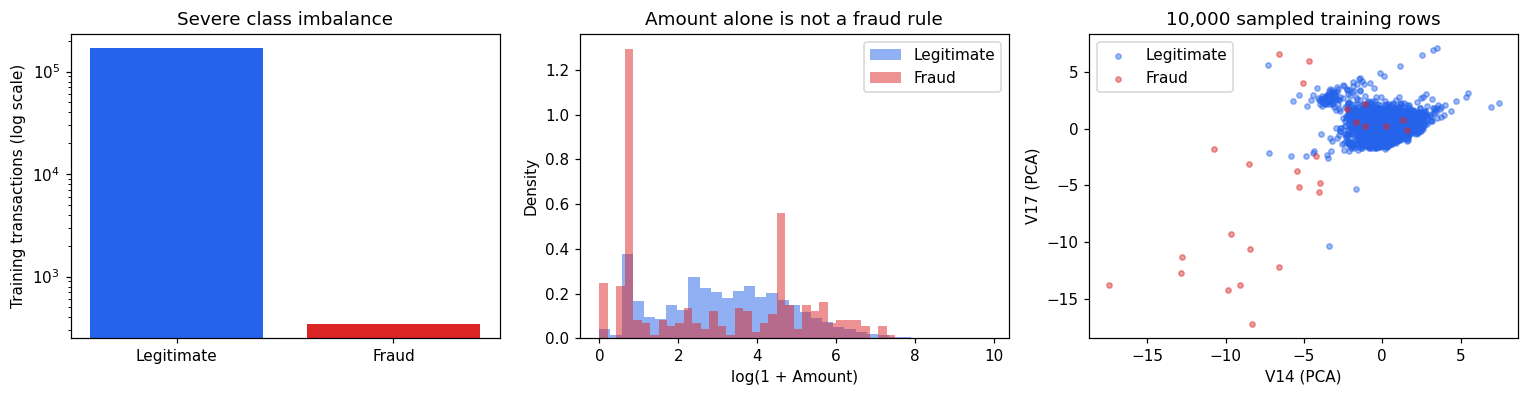

Always-legitimate training accuracy: 99.7991%; fraud recall: 0%.


In [0]:
display(train.groupby('Class')['Amount'].describe())
fig, axes = plt.subplots(1, 3, figsize=(14, 3.7))
counts = train['Class'].value_counts().reindex([0, 1])
axes[0].bar(['Legitimate', 'Fraud'], counts, color=['#2563eb', '#dc2626'])
axes[0].set_yscale('log')
axes[0].set_ylabel('Training transactions (log scale)')
axes[0].set_title('Severe class imbalance')
for label, color in [(0, '#2563eb'), (1, '#dc2626')]:
    values = np.log1p(train.loc[train['Class'] == label, 'Amount'])
    axes[1].hist(values, bins=35, density=True, alpha=0.5, color=color,
                 label='Fraud' if label else 'Legitimate')
axes[1].set(xlabel='log(1 + Amount)', ylabel='Density', title='Amount alone is not a fraud rule')
axes[1].legend()
scatter = train.sample(n=min(10000, len(train)), random_state=SEED)
for label, color in [(0, '#2563eb'), (1, '#dc2626')]:
    points = scatter.loc[scatter['Class'] == label]
    axes[2].scatter(points['V14'], points['V17'], s=12, alpha=0.45,
                    color=color, label='Fraud' if label else 'Legitimate')
axes[2].set(xlabel='V14 (PCA)', ylabel='V17 (PCA)', title='10,000 sampled training rows')
axes[2].legend()
fig.tight_layout()
plt.show()
print(f'Always-legitimate training accuracy: {1 - train["Class"].mean():.4%}; fraud recall: 0%.')


## 6. Prepare predictors without leaking the label

Use `V1`–`V28` plus `LogAmount`. Exclude `Class` and exclude `Time` as a predictor so the
model cannot rely directly on the arbitrary elapsed-seconds origin. The time column still
defines our evaluation order. `log1p` is a fixed row-wise transform; it learns no statistics.
The logistic-regression scaler is fitted later inside a pipeline on training rows only.


In [0]:
FEATURES = [f'V{i}' for i in range(1, 29)] + ['LogAmount']

def make_features(frame):
    features = frame[[f'V{i}' for i in range(1, 29)]].copy()
    features['LogAmount'] = np.log1p(frame['Amount'])
    assert list(features.columns) == FEATURES
    assert np.isfinite(features.to_numpy()).all()
    return features

X_train, y_train = make_features(train), train['Class'].astype(int)
X_validation, y_validation = make_features(validation), validation['Class'].astype(int)
assert 'Class' not in FEATURES and 'Time' not in FEATURES
print('Predictor matrix:', X_train.shape)


Predictor matrix: (170236, 29)


## 7. What will we train, and why?

| Model | Learning setup | Purpose and key choices |
|---|---|---|
| Always legitimate | Dummy baseline | Demonstrates why accuracy alone is misleading |
| Logistic regression | Supervised | A linear log-odds baseline; scaling and balanced class weights |
| Decision tree | Supervised | Interpretable nonlinear splits; depth 4 and minimum 20 rows per leaf |
| Random forest | Supervised | Averages 100 randomized trees; depth 12 and minimum 5 rows per leaf |
| Isolation Forest | Unsupervised fitting | Finds easily isolated observations; 100 trees and 256 sampled rows per tree |

Decision trees choose feature/threshold splits that reduce weighted class impurity.
For class proportions p₀ and p₁, **Gini = 1 − p₀² − p₁²**. A pure node has Gini zero.
`max_depth` limits successive decisions; `min_samples_leaf` limits very small leaves.
With `class_weight='balanced'`, training examples receive weights inversely proportional
to class frequency. Weighted leaf scores should not be read as calibrated real-world
fraud probabilities. The forest uses `balanced_subsample` to recompute those weights
within each bootstrap sample. A forest is usually harder to explain than one small tree.

Isolation Forest fits **all X_train without using y_train**. We negate `score_samples`
because lower original scores mean more anomalous. Its resulting risk is not a probability.
We evaluate it with labels afterward; selecting an operating threshold using labeled
validation data makes that deployment decision label-informed [3–6]. An anomaly is not
automatically fraud. Hyperparameters below are fixed teaching choices, not an exhaustive search.


In [0]:
models = {
    'Always legitimate': DummyClassifier(strategy='constant', constant=0),
    'Logistic regression': Pipeline([
        ('scale', StandardScaler()),
        ('model', LogisticRegression(class_weight='balanced', max_iter=1500,
                                     solver='lbfgs', random_state=SEED)),
    ]),
    'Decision tree': DecisionTreeClassifier(
        max_depth=4, min_samples_leaf=20, class_weight='balanced', random_state=SEED),
    'Random forest': RandomForestClassifier(
        n_estimators=100, max_depth=12, min_samples_leaf=5,
        class_weight='balanced_subsample', n_jobs=2, random_state=SEED),
    'Isolation Forest': IsolationForest(
        n_estimators=100, max_samples=256, contamination='auto',
        n_jobs=2, random_state=SEED),
}

fit_seconds = {}
for name, model in models.items():
    started = time.perf_counter()
    if name == 'Isolation Forest':
        model.fit(X_train)  # No labels are supplied.
    else:
        model.fit(X_train, y_train)
    fit_seconds[name] = time.perf_counter() - started
display(pd.Series(fit_seconds, name='fit_seconds').to_frame().round(2))


,fit_seconds
Always legitimate,0.07
Logistic regression,3.63
Decision tree,5.90
Random forest,85.23
Isolation Forest,0.62


## 8. Use metrics that answer the fraud-detection question

**Precision = TP/(TP+FP):** how many alerts are actual frauds?

**Recall = TP/(TP+FN):** how many frauds did we detect?

**F1:** harmonic mean of precision and recall at one threshold.

**Average precision (AP):** summarizes precision–recall ranking across thresholds [7].
AP is not identical to trapezoidal PR-AUC. 

**ROC-AUC:** ranking of fraud versus legitimate
transactions; useful alongside AP, but it does not describe alert workload.

**Alert rate:** fraction of transactions sent for review. A constant score's AP equals
the positive prevalence; ROC-AUC is 0.5 when both classes exist.

First compare rankings on validation data. Then report threshold-dependent metrics at
`0.5` for supervised scores and the Isolation Forest default anomaly boundary. These
defaults are starting points, not optimized policies. Zero precision is reported when
there are no positive predictions. All counts and metrics are unweighted on natural data.


,threshold,AP,ROC_AUC,precision,recall,F1,accuracy,alert_rate,TN,FP,FN,TP
model,,,,,,,,,,,,
Random forest,0.5,0.76353,0.95796,0.93333,0.73684,0.82353,0.99968,0.00079,56686,3,15,42
Logistic regression,0.5,0.75319,0.96910,0.02417,0.89474,0.04707,0.96361,0.03718,54630,2059,6,51
Decision tree,0.5,0.50805,0.87547,0.01550,0.80702,0.03041,0.94831,0.05230,53767,2922,11,46
Isolation Forest,0.5,0.01837,0.93706,0.01755,0.77193,0.03432,0.95637,0.04418,54226,2463,13,44
Always legitimate,0.5,0.00100,0.50000,0.00000,0.00000,0.00000,0.99900,0.00000,56689,0,57,0


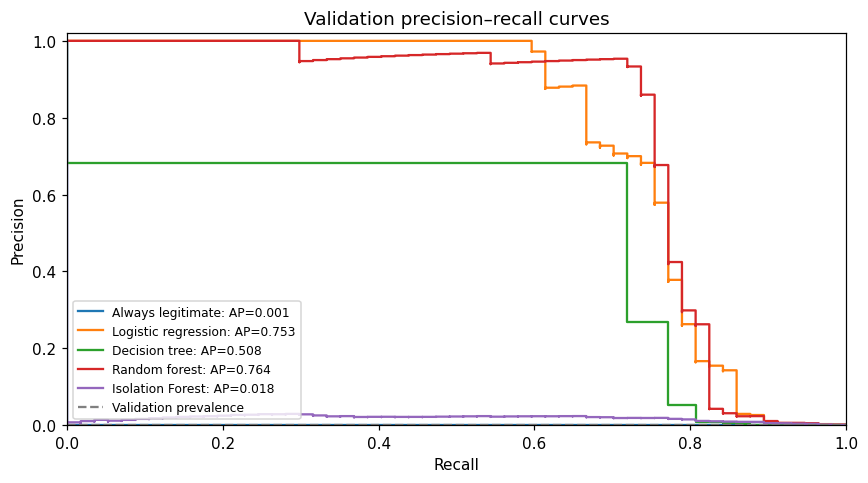

In [0]:
def risk_scores(name, model, features):
    if name == 'Isolation Forest':
        return -model.score_samples(features)
    fraud_column = int(np.flatnonzero(model.classes_ == 1)[0])
    return model.predict_proba(features)[:, fraud_column]

def operating_metrics(labels, scores, threshold):
    predictions = (np.asarray(scores) >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(labels, predictions, labels=[0, 1]).ravel()
    return {
        'threshold': float(threshold), 'AP': average_precision_score(labels, scores),
        'ROC_AUC': roc_auc_score(labels, scores),
        'precision': precision_score(labels, predictions, zero_division=0),
        'recall': recall_score(labels, predictions, zero_division=0),
        'F1': f1_score(labels, predictions, zero_division=0),
        'accuracy': accuracy_score(labels, predictions), 'alert_rate': predictions.mean(),
        'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp),
    }

validation_scores = {}
default_thresholds = {}
validation_rows = []
for name, model in models.items():
    scores = risk_scores(name, model, X_validation)
    validation_scores[name] = scores
    threshold = -float(model.offset_) if name == 'Isolation Forest' else 0.5
    default_thresholds[name] = threshold
    validation_rows.append({'model': name, **operating_metrics(y_validation, scores, threshold)})
validation_metrics = pd.DataFrame(validation_rows).set_index('model')
display(validation_metrics.sort_values('AP', ascending=False).round(5))

fig, ax = plt.subplots(figsize=(8, 4.5))
for name, scores in validation_scores.items():
    precision, recall, _ = precision_recall_curve(y_validation, scores)
    ax.step(recall, precision, where='post',
            label=f'{name}: AP={average_precision_score(y_validation, scores):.3f}')
ax.axhline(y_validation.mean(), color='gray', linestyle='--', label='Validation prevalence')
ax.set(xlabel='Recall', ylabel='Precision', title='Validation precision–recall curves',
       xlim=(0, 1), ylim=(0, 1.02))
ax.legend(loc='lower left', fontsize=8)
fig.tight_layout()
plt.show()


## 9. Inspect the tree rather than treating it as a black box

The fitted tree has at most four decision levels. The diagram shows only its first three
levels for readability; text rules expose all fitted levels. Follow one path: a left branch
means the displayed `feature <= threshold` condition is true. A leaf predicts a class using
weighted training counts. Because class weighting is used, node proportions and class values
reflect weights; `samples` counts underlying training rows. PCA names such as V14 are not
merchant categories or human-readable financial explanations.

Impurity importance tells us which features reduced training impurity; it does not prove
causality or stability. Correlated predictors can share/substitute importance. This visualization
explains the decision tree even if another model wins the validation comparison.


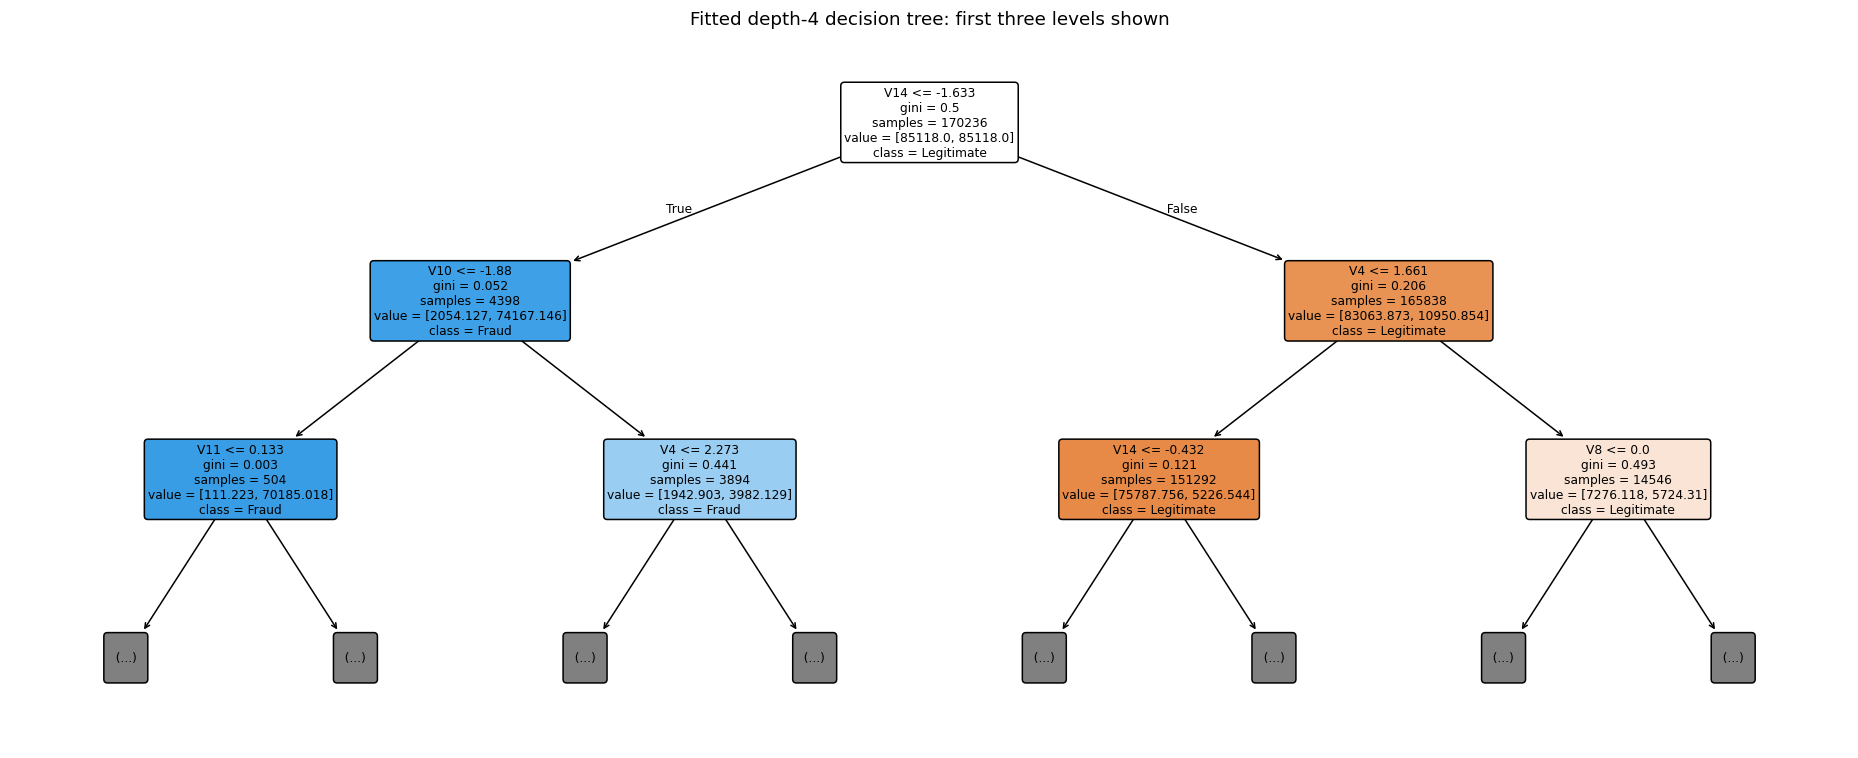

|--- V14 <= -1.633
|   |--- V10 <= -1.880
|   |   |--- V11 <= 0.133
|   |   |   |--- class: 0
|   |   |--- V11 >  0.133
|   |   |   |--- V14 <= -2.733
|   |   |   |   |--- class: 1
|   |   |   |--- V14 >  -2.733
|   |   |   |   |--- class: 1
|   |--- V10 >  -1.880
|   |   |--- V4 <= 2.273
|   |   |   |--- V21 <= 0.119
|   |   |   |   |--- class: 0
|   |   |   |--- V21 >  0.119
|   |   |   |   |--- class: 1
|   |   |--- V4 >  2.273
|   |   |   |--- V7 <= 0.332
|   |   |   |   |--- class: 1
|   |   |   |--- V7 >  0.332
|   |   |   |   |--- class: 0
|--- V14 >  -1.633
|   |--- V4 <= 1.661
|   |   |--- V14 <= -0.432
|   |   |   |--- V20 <= -0.510
|   |   |   |   |--- class: 1
|   |   |   |--- V20 >  -0.510
|   |   |   |   |--- class: 0
|   |   |--- V14 >  -0.432
|   |   |   |--- V7 <= 1.302
|   |   |   |   |--- class: 0
|   |   |   |--- V7 >  1.302
|   |   |   |   |--- class: 0
|   |--- V4 >  1.661
|   |   |--- V8 <= 0.000
|   |   |   |--- V12 <= -0.284
|   |   |   |   |--- class: 1
|   | 

,impurity_importance
V14,0.849396
V4,0.061438
V8,0.025559
V10,0.015794
V12,0.011269
V20,0.010507
V21,0.009380
V7,0.008856
V19,0.007098
V11,0.000705


In [0]:
tree_model = models['Decision tree']
fig, ax = plt.subplots(figsize=(17, 7))
plot_tree(tree_model, feature_names=FEATURES, class_names=['Legitimate', 'Fraud'],
          filled=True, rounded=True, max_depth=2, fontsize=8, ax=ax)
ax.set_title('Fitted depth-4 decision tree: first three levels shown')
fig.tight_layout()
plt.show()
print(export_text(tree_model, feature_names=FEATURES, decimals=3))
tree_importance = pd.Series(tree_model.feature_importances_, index=FEATURES).sort_values(ascending=False)
display(tree_importance.head(10).rename('impurity_importance').to_frame())


## 10. Freeze a model and choose the review threshold on validation only

The declared model-selection rule is **highest validation AP among supervised candidates**:
logistic regression, decision tree, and random forest. Isolation Forest is an anomaly-detection
comparison and the dummy is a baseline. We do not pick a winner using test results.

The declared operating policy is **at least 80% validation recall; among feasible thresholds,
maximize validation precision**. Break ties by choosing the higher threshold. This is an
illustrative teaching policy, not a bank's contractual target. `precision_recall_curve`
returns one extra precision/recall endpoint without a threshold, so we drop that endpoint.
Thresholds on continuous scores need not be 0.5. Validation has few frauds, so the selected
threshold is uncertain and 80% recall is not guaranteed on future data.

We keep the selected fitted model unchanged: refitting on training+validation would change
its score distribution and invalidate the threshold chosen for the old model [8].


Selected model: Random forest


,validation_at_frozen_threshold
threshold,0.109629
AP,0.763528
ROC_AUC,0.957958
precision,0.298701
recall,0.807018
F1,0.436019
accuracy,0.997903
alert_rate,0.002714
TN,56581.000000
FP,108.000000


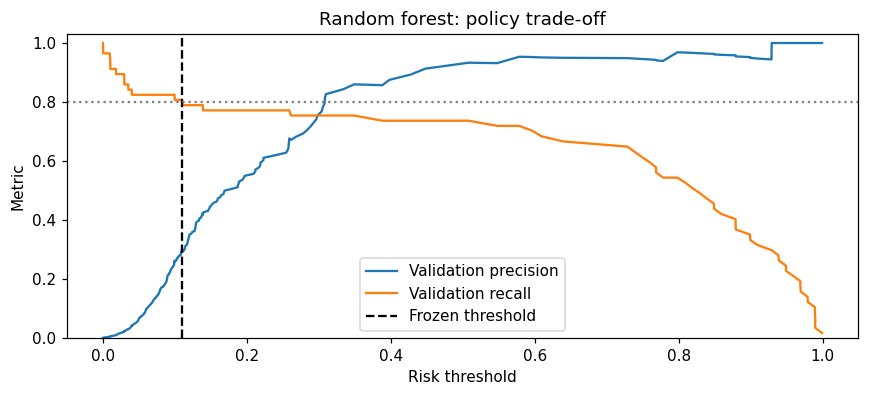

In [0]:
supervised_candidates = ['Logistic regression', 'Decision tree', 'Random forest']
selected_name = validation_metrics.loc[supervised_candidates, 'AP'].idxmax()
selected_model = models[selected_name]
TARGET_RECALL = 0.80

precision, recall, thresholds = precision_recall_curve(
    y_validation, validation_scores[selected_name])
threshold_table = pd.DataFrame({
    'threshold': thresholds, 'precision': precision[:-1], 'recall': recall[:-1],
})
feasible = threshold_table.loc[threshold_table['recall'] >= TARGET_RECALL]
if feasible.empty:
    raise RuntimeError('No validation threshold satisfies the declared recall policy.')
chosen = feasible.sort_values(['precision', 'threshold'], ascending=[False, False]).iloc[0]
selected_threshold = float(chosen['threshold'])
validation_selected = operating_metrics(
    y_validation, validation_scores[selected_name], selected_threshold)
assert validation_selected['recall'] >= TARGET_RECALL
print('Selected model:', selected_name)
display(pd.Series(validation_selected, name='validation_at_frozen_threshold').to_frame())

fig, ax = plt.subplots(figsize=(8, 3.7))
ax.plot(threshold_table['threshold'], threshold_table['precision'], label='Validation precision')
ax.plot(threshold_table['threshold'], threshold_table['recall'], label='Validation recall')
ax.axvline(selected_threshold, color='black', linestyle='--', label='Frozen threshold')
ax.axhline(TARGET_RECALL, color='gray', linestyle=':')
ax.set(xlabel='Risk threshold', ylabel='Metric', title=f'{selected_name}: policy trade-off', ylim=(0, 1.03))
ax.legend()
fig.tight_layout()
plt.show()


## 11. Evaluate the frozen policy once on the future test window

This is the first use of test rows for model prediction/evaluation. Compare the selected
model at its default threshold versus its validation-selected threshold, plus the dummy.
The comparison is explanatory: **do not switch thresholds or models after seeing this table**.

Rows in the confusion matrix are actual classes; columns are predicted classes. False
negatives are missed frauds. False positives are legitimate transactions requiring review.
A high recall with too many false positives may exceed an analyst team's capacity.

Wilson intervals below communicate uncertainty from the small number of labeled frauds and
alerts. They use a binomial approximation and do not model dependence between transactions
or uncertainty from model/threshold selection. Distribution shift is another source of error.


,threshold,AP,ROC_AUC,precision,recall,F1,accuracy,alert_rate,TN,FP,FN,TP
policy,,,,,,,,,,,,
Always legitimate,0.50000,0.00130,0.5000,0.00000,0.00000,0.00000,0.99870,0.00000,56670,0,74,0
Random forest: default,0.50000,0.81456,0.9401,0.88889,0.75676,0.81752,0.99956,0.00111,56663,7,18,56
Random forest: frozen validation policy,0.10963,0.81456,0.9401,0.38037,0.83784,0.52321,0.99801,0.00287,56569,101,12,62


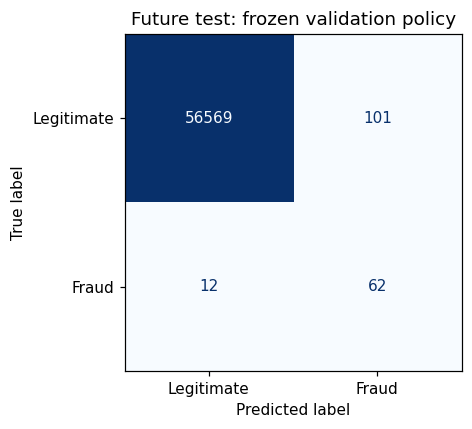

,metric,estimate,lower_95,upper_95
0,recall,0.837838,0.737600,0.904730
1,precision,0.380368,0.309404,0.456841


In [0]:
X_test, y_test = make_features(test), test['Class'].astype(int)
test_scores = risk_scores(selected_name, selected_model, X_test)
test_results = operating_metrics(y_test, test_scores, selected_threshold)
test_default = operating_metrics(y_test, test_scores, default_thresholds[selected_name])
dummy_scores = risk_scores('Always legitimate', models['Always legitimate'], X_test)
test_baseline = operating_metrics(y_test, dummy_scores, 0.5)
test_comparison = pd.DataFrame([
    {'policy': 'Always legitimate', **test_baseline},
    {'policy': f'{selected_name}: default', **test_default},
    {'policy': f'{selected_name}: frozen validation policy', **test_results},
]).set_index('policy')
display(test_comparison.round(5))

test_predictions = (test_scores >= selected_threshold).astype(int)
fig, ax = plt.subplots(figsize=(5.5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, test_predictions, labels=[0, 1], display_labels=['Legitimate', 'Fraud'],
    cmap='Blues', colorbar=False, values_format='d', ax=ax)
ax.set_title('Future test: frozen validation policy')
fig.tight_layout()
plt.show()

def wilson_interval(successes, trials, z=1.96):
    if trials == 0:
        return (float('nan'), float('nan'))
    p = successes / trials
    denominator = 1 + z * z / trials
    center = (p + z * z / (2 * trials)) / denominator
    margin = z * np.sqrt(p * (1 - p) / trials + z * z / (4 * trials * trials)) / denominator
    return float(center - margin), float(center + margin)

recall_interval = wilson_interval(test_results['TP'], test_results['TP'] + test_results['FN'])
precision_interval = wilson_interval(test_results['TP'], test_results['TP'] + test_results['FP'])
display(pd.DataFrame([
    {'metric': 'recall', 'estimate': test_results['recall'], 'lower_95': recall_interval[0], 'upper_95': recall_interval[1]},
    {'metric': 'precision', 'estimate': test_results['precision'], 'lower_95': precision_interval[0], 'upper_95': precision_interval[1]},
]))


## 12. Convert predictions into workload and an illustrative cost scenario

An alert means **send for review**, not automatically block or declare guilt. Report alerts
per 10,000 observed test transactions. The following cost function assumes every missed
fraud costs 100 currency units and every false alert costs 1 unit. These are explicitly
invented classroom assumptions, not amounts inferred from the dataset or a production ROI.
It omits true-positive investigation cost, recovery, customer friction, and unequal fraud amounts.
Change these assumptions to discuss policy, without retuning on test outcomes.


In [0]:
COST_MISSED_FRAUD = 100.0
COST_FALSE_ALERT = 1.0
cost_scenario = test_comparison[['FP', 'FN', 'TP', 'alert_rate']].copy()
cost_scenario['alerts_per_10000'] = 10000 * cost_scenario['alert_rate']
cost_scenario['illustrative_cost'] = (
    COST_MISSED_FRAUD * cost_scenario['FN'] + COST_FALSE_ALERT * cost_scenario['FP'])
display(cost_scenario.round(2))
print(f'Frozen policy sends {test_predictions.sum():,} of {len(test):,} transactions for review.')


,FP,FN,TP,alert_rate,alerts_per_10000,illustrative_cost
policy,,,,,,
Always legitimate,0,74,0,0.0,0.00,7400.0
Random forest: default,7,18,56,0.0,11.10,1807.0
Random forest: frozen validation policy,101,12,62,0.0,28.73,1301.0


Frozen policy sends 163 of 56,744 transactions for review.


## 13. Score new records with the same transformations and policy

This function checks the required numeric inputs, applies the same `make_features` transform,
and returns risk plus a review flag. `Class` and `Time` are not required. The score is a model
risk estimate, not an assertion of fraud. The example uses five held-out test transactions
only to demonstrate the interface; it is not an additional performance estimate or a new model fit.


In [0]:
def score_transactions(frame):
    required = [f'V{i}' for i in range(1, 29)] + ['Amount']
    missing = sorted(set(required) - set(frame.columns))
    if missing:
        raise ValueError(f'Missing required columns: {missing}')
    if not all(pd.api.types.is_numeric_dtype(frame[c]) for c in required):
        raise ValueError('Required inputs must have numeric dtypes.')
    values = frame[required].to_numpy(dtype=float)
    if not np.isfinite(values).all() or frame['Amount'].lt(0).any():
        raise ValueError('Inputs must be finite and Amount must be nonnegative.')
    scores = risk_scores(selected_name, selected_model, make_features(frame))
    return pd.DataFrame({
        'risk_score': scores, 'review_flag': (scores >= selected_threshold).astype(int),
    }, index=frame.index)

demo_input = test.head(5).drop(columns=['Class', 'Time'])
demo_scores = score_transactions(demo_input)
assert np.allclose(demo_scores['risk_score'], test_scores[:5])
display(demo_scores)


,risk_score,review_flag
226982,0.000000,0
226983,0.017814,0
226984,0.000662,0
226985,0.015272,0
226986,0.039519,0


## 14. Export reproducible evaluation artifacts

Save the audit, split counts, validation comparison, frozen-policy test comparison,
row-level test scores, and a manifest recording the dataset hash, environment, features,
hyperparameters, and threshold. `source_row_after_dedup` is a local row reference, not a
real transaction ID. No sensitive original card identifiers are available in this benchmark.

The default output folder is temporary. In Colab download artifacts through the Files panel;
on Databricks set `OUTPUT_DIR` in Section 1 to an authorized `/Volumes/...` folder for durable
outputs. The model remains in memory; the CSV/JSON exports alone are not a deployable model.


In [0]:
audit.to_csv(OUTPUT_DIR / 'data_audit.csv', index=False)
split_summary.to_csv(OUTPUT_DIR / 'split_summary.csv', index=False)
validation_metrics.to_csv(OUTPUT_DIR / 'validation_metrics.csv')
test_comparison.to_csv(OUTPUT_DIR / 'test_metrics.csv')
scored_test = pd.DataFrame({
    'source_row_after_dedup': test.index, 'Time': test['Time'].to_numpy(),
    'Amount': test['Amount'].to_numpy(), 'actual_class': y_test.to_numpy(),
    'risk_score': test_scores, 'review_flag': test_predictions,
})
scored_test.to_csv(OUTPUT_DIR / 'test_scores.csv', index=False)
manifest = {
    'dataset_url': DATA_URL, 'dataset_sha256': dataset_sha256,
    'original_rows': len(raw), 'deduplicated_rows': len(data),
    'duplicate_policy': 'keep first exact row', 'seed': SEED,
    'split': 'chronological quantiles 60/20/20; tied timestamps kept together',
    'train_cut_seconds': float(train_cut), 'validation_cut_seconds': float(validation_cut),
    'features': FEATURES, 'versions': versions, 'selected_model': selected_name,
    'selected_model_parameters': {
        key: value for key, value in selected_model.get_params().items()
        if value is None or isinstance(value, (str, bool, int, float))
    },
    'selection_metric': 'validation average precision, supervised candidates only',
    'target_validation_recall': TARGET_RECALL, 'selected_threshold': selected_threshold,
    'validation_metrics_at_selected_threshold': validation_selected,
    'test_metrics_at_selected_threshold': test_results,
    'test_recall_wilson_95': recall_interval,
    'test_precision_wilson_95': precision_interval,
    'cost_assumptions': {'missed_fraud': COST_MISSED_FRAUD, 'false_alert': COST_FALSE_ALERT},
}
with (OUTPUT_DIR / 'run_manifest.json').open('w') as handle:
    json.dump(manifest, handle, indent=2, allow_nan=False)
print('Artifacts:', OUTPUT_DIR)
print('\n'.join(sorted(path.name for path in OUTPUT_DIR.iterdir() if path.is_file())))


Artifacts: /tmp/fraud_demo_outputs
data_audit.csv
run_manifest.json
split_summary.csv
test_metrics.csv
test_scores.csv
validation_metrics.csv


## 15. Optional: track the verified experiment with MLflow

Skip this section for the core workshop. To enable it, install MLflow if absent, set
`RUN_MLFLOW=True`, and rerun this section after the main workflow. In Databricks, set
`MLFLOW_EXPERIMENT` to an experiment path in your workspace that you can write to; it has
no hard-coded experiment ID. In Colab, an unset tracking URI uses a local temporary tracking
directory; this does not create a hosted Databricks experiment or UI.

This logs the **actual selected fitted model**, its validation-selected threshold, the
input signature, and the same test metrics you just computed. The logged sklearn model
expects the 29 **engineered** features, not raw `Amount`; the manifest specifies how to
construct them. The review threshold is a run parameter and must also be applied by a
serving wrapper. This is experiment tracking, not production deployment. This optional
integration needs a working MLflow installation and credentials/permissions if using a
remote server; it is not exercised by the default local verification.


In [0]:
if RUN_MLFLOW:
    import os
    import mlflow
    import mlflow.sklearn
    from mlflow.models import infer_signature

    if not os.environ.get('DATABRICKS_RUNTIME_VERSION') and not os.environ.get('MLFLOW_TRACKING_URI'):
        mlflow.set_tracking_uri((Path(tempfile.gettempdir()) / 'fraud_demo_mlflow').as_uri())
    if MLFLOW_EXPERIMENT:
        mlflow.set_experiment(MLFLOW_EXPERIMENT)
    elif not os.environ.get('DATABRICKS_RUNTIME_VERSION'):
        mlflow.set_experiment('financial_fraud_teaching_demo')

    with mlflow.start_run(run_name='chronological_fraud_demo'):
        mlflow.log_params({
            'selected_model': selected_name, 'seed': SEED,
            'review_threshold': selected_threshold, 'validation_recall_target': TARGET_RECALL,
            'dataset_sha256': dataset_sha256, 'split_policy': 'chronological_60_20_20',
        })
        mlflow.log_metrics({f'test_{key}': float(value) for key, value in test_results.items()})
        signature = infer_signature(X_train.head(5), selected_model.predict(X_train.head(5)))
        mlflow.sklearn.log_model(
            selected_model, artifact_path='model', signature=signature,
            input_example=X_train.head(5),
        )
        mlflow.log_artifact(str(OUTPUT_DIR / 'run_manifest.json'))
        mlflow.log_artifact(str(OUTPUT_DIR / 'validation_metrics.csv'))
        mlflow.log_artifact(str(OUTPUT_DIR / 'test_metrics.csv'))
        print('MLflow run:', mlflow.active_run().info.run_id)
else:
    print('Optional MLflow logging is disabled; core demo is complete.')


Optional MLflow logging is disabled; core demo is complete.


## 16. Student analysis and controlled extensions

Answer using your own run's tables and figures. To support your understanding use Genie. However, I recommend you understand the fundamentals.

1. Calculate the dummy's accuracy, recall, and AP. Why do they tell different stories?
2. Trace one path through the decision tree. Explain Gini, depth, leaf size, and class weighting.
3. Which supervised model won validation AP? Is the highest ROC-AUC model necessarily the
   best choice for a limited review budget?
4. Compare the default and frozen thresholds: how many false positives and false negatives
   changed on test? Explain why the 80% validation recall target need not hold on test.
5. Explain why Isolation Forest's training is unsupervised, but our label-based evaluation
   is not. Would every unusual transaction be fraud?
6. Explain why replacing every missing value with zero, balancing test data, or fitting a
   scaler before the split can produce misleading conclusions.
7. Discuss the duplicate-removal assumption, supplied PCA limitations, missing customer IDs, and privacy. What evidence is needed before deployment?
8. Report the frozen policy's precision/recall intervals and alert workload. Could an analyst
   team handle it? Why is the invented cost scenario not a business case?

**Extensions require a new development protocol.** Keep this test window closed. On training
and validation only, compare depths 3/4/6, tune a review-budget policy, or add gradient boosting.

**optional** If you use SMOTE or resampling, apply it only within training folds, never before splitting.
Use forward-chaining validation for temporal tuning and arrange a new future holdout for a
new final claim. Do not repeatedly tune after inspecting this notebook's test results.

**Suggested student deliverable:** one PDF with the audit, split table, tree explanation,
validation comparison, frozen threshold justification, test confusion matrix, workload,
limitations, and answers to Questions 1–8. Include the notebook and manifest as reproducibility files.


## 17. References and dataset attribution

1. Worldline and Machine Learning Group, Université Libre de Bruxelles.
   *Credit Card Fraud Detection* (original dataset listing):
   https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud
   Review the original dataset's current usage/license terms before redistribution.
2. TensorFlow. *Classification on imbalanced data*. Official description and public CSV mirror:
   https://www.tensorflow.org/tutorials/structured_data/imbalanced_data
   CSV: https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv
3. Lucas, Y., and Jurgovsky, J. (2020). *Credit card fraud detection using machine learning:
   A survey*. arXiv:2010.06479. https://arxiv.org/abs/2010.06479
   Background for imbalance, evaluation, temporal behavior, and concept drift.
4. Niu, X., Wang, L., and Yang, X. (2019). *A Comparison Study of Credit Card Fraud Detection:
   Supervised versus Unsupervised*. arXiv:1904.10604. https://arxiv.org/abs/1904.10604
   Motivation for supervised/unsupervised comparisons; this notebook does not reproduce its protocol/results.
5. scikit-learn. *Decision Trees*. https://scikit-learn.org/stable/modules/tree.html
6. scikit-learn. *IsolationForest* API and original algorithm references.
   https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.IsolationForest.html
7. scikit-learn. *Precision-Recall*.
   https://scikit-learn.org/stable/auto_examples/model_selection/plot_precision_recall.html
8. scikit-learn. *Tuning the decision threshold for class prediction*.
   https://scikit-learn.org/stable/modules/classification_threshold.html
9. Databricks. *Import and export Databricks notebooks*.
   https://docs.databricks.com/aws/en/notebooks/notebook-export-import
10. Original Databricks PaySim example supplied for context:
    https://pages.databricks.com/rs/094-YMS-629/images/financial-fraud-detection-decision-tree.html

Sources and dataset access checked November 12, 2026. All modeling code in this notebook is
a new teaching implementation; published benchmark scores are not presented as our results.
